# Week 7 · Shear hands-on: Shapes in real data with DP2 and the LSST Science Pipelines

In this notebook we work with **real LSSTCam data** from **Data Preview 2 (DP2)**, and run the first steps of a weak-lensing measurement ourselves, with the **LSST Science Pipelines**, the software Rubin's Data Management (DM) uses to make the data products:

1. find a small patch of sky in the DP2 footprint, and look at its deep coadded images and its PSF;
2. **detect** the objects, and **deblend** those that overlap;
3. **measure their shapes** with adaptive moments (HSM);
4. look at the basic **properties of the galaxies**: magnitude, size, shape;
5. **average the shapes** over the patch, and compare them with the PSF.

Every catalogue in this notebook is our own: we use DP2's images, not its catalogues.

**The data.** DP2 contains LSSTCam images taken during commissioning and science validation, processed with version 30 of the pipelines. We use the deep coadds of one patch (11′ × 11′) in the Extended Chandra Deep Field South (ECDFS), one of the Deep Drilling Fields.

**How to use it.** Run on the Rubin Science Platform (<https://data.lsst.cloud>) with the **LSST** kernel. The notebook needs about 2 GB of memory; use a **Large** server, as the DP2 tutorials recommend. Run the cells in order, because later sections use the objects made earlier. Running every cell takes about a minute; the first run is slower, because the Butler fetches the data. The **Questions** after each section are to think about; Section 8, *Going further*, has exercises that need some code.

**AI-use note.** This notebook was developed with the help of an AI assistant, Claude Opus 5.5 (Anthropic; model ID `claude-opus-5-5`), used through Claude Code. It drafted and revised the text and the code, ran the analyses, and checked the numbers quoted in the text against the outputs.

**Words you will meet.** *Butler*: the pipelines' interface to the data; you ask it for a dataset type (`deep_coadd`, `skyMap`, ...) and a data ID (band, tract, patch). *Skymap*, *tract*, *patch*: the sky is tiled into tracts of about 1.66° × 1.66°, each cut into 10 × 10 overlapping patches of 11′; the coadds are made per patch. *Coadd*: the weighted sum of all the visits of a patch, deeper than any single image; DP2's coadds are *cell-based*: each 150 × 150-pixel (30″) cell is built from its own set of input visits, and has its own PSF. *PSF*: the point-spread function, here modelled per visit with PIFF and combined over the coadd. *Footprint*: the pixels of one detection above the threshold; its *peaks* are local maxima. *Deblending*: splitting a footprint with several peaks (a *parent*) into *children*. *Adaptive moments* (HSM): the second moments $I_{xx}, I_{yy}, I_{xy}$ of an object, measured with an elliptical Gaussian weight matched to it; their trace $T = I_{xx} + I_{yy}$ measures the size. *Distortion* $e$: an ellipticity from moments, $e_1 = (I_{xx} - I_{yy})/T$, $e_2 = 2 I_{xy}/T$; for a small shear, $e \approx 2g$. *Re-Gaussianization*: the HSM method that removes the PSF from the moments (Hirata & Seljak 2003). *Resolution* $R_2$: 0 for a point source, 1 for an object much larger than the PSF. *Responsivity* $\mathcal{R}$: converts a mean distortion into a shear, $g = \langle e\rangle / 2\mathcal{R}$. *Provenance*: the record of the input images that went into a coadd. *Dither*: a shift of the pointing between visits, so that the gaps between detectors fall on different parts of the sky. *PSF leakage* $\alpha$ and *additive bias* $c$: in $\langle g\rangle = \alpha\, g_{\rm PSF} + c$, the part of the PSF ellipticity that leaks into the galaxy shapes, and any other spurious mean shear.

## 0. Setup

The pipelines' measurement tasks find their plugins in a registry; the `ext_shapeHSM_*` plugins (HSM moments and shapes) only appear there after `import lsst.meas.extensions.shapeHSM`.

In [1]:
import logging

import galsim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.visualization import make_lupton_rgb
from matplotlib.colors import LogNorm

import lsst.geom as geom
from lsst.sphgeom import LonLat
import lsst.afw.image as afwImage
import lsst.afw.table as afwTable
from lsst.daf.butler import Butler
import lsst.meas.extensions.shapeHSM
from lsst.meas.deblender import SourceDeblendTask
from lsst.meas.algorithms import SourceDetectionTask
from lsst.meas.base import SingleFrameMeasurementTask

RA, DEC = 53.13, -28.10      # the centre of the ECDFS deep field, in degrees
BAND = 'r'
SKYMAP = 'lsst_cells_v2'
PIXEL_SCALE = 0.2            # arcsec per pixel
ZP_NJY = 31.4                # the coadds are in nJy: mag = 31.4 - 2.5 log10(flux / nJy)
SIGMA_TO_FWHM = 2 * np.sqrt(2 * np.log(2))

logging.getLogger('lsst').setLevel(logging.WARNING)                # the tasks report a lot
logging.getLogger('lsst.measurement').setLevel(logging.ERROR)      # e.g. PSF fluxes on the few empty pixels
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

butler = Butler('dp2', collections='dp2')
skymap = butler.get('skyMap', skymap=SKYMAP)

## 1. Where we are: the DP2 footprint and our patch

DP2 has deep coadds over the Wide-Fast-Deep, the small survey fields and the Deep Drilling Fields observed during science validation. We ask the Butler which tracts have an r-band coadd, and which tract and patch contain the ECDFS centre. The coadds' input summary, `deep_coadd_input_summary`, lists every image that went into every patch's coadd. From it we count, for each tract, the distinct r-band visits (each visit is one exposure), and colour the map with that number.

**Tracts, patches and cells.** DP2 divides the sky on three levels:

| level | size | what it is |
|---|---|---|
| tract | about 1.7° × 1.7° | a region of the sky map, cut into 10 × 10 patches |
| patch | 3300 × 3300 pixels, 11′ | the unit the coadds are made for; neighbouring patches overlap |
| cell | 150 × 150 pixels, 30″ | a piece of a patch's coadd, built from its own set of input visits, with its own PSF |

A patch holds 22 × 22 = 484 cells. The patch is how the sky is divided into files; the cell is the size on which the coadd is internally consistent, because the same images were added everywhere inside it.

**The data we use.** Everything in this notebook is *coadded* data: we never use the single-visit images, only their record in each cell's provenance (Section 2). Apart from the map of this section, we use **one patch** (tract 5063, patch 14): its g, r and i coadds, and our own catalogue, which we make by detecting, deblending and measuring its r-band coadd. Section 2 also looks inside the patch, cell by cell. We use no catalogue from DP2's own processing: every measurement is ours.

(RA, Dec) = (53.13, -28.1) is in tract 5063, patch 14


1999 tracts have an r-band deep coadd, made from 1 to 356 r-band visits (median 12); tract 5063 has 37


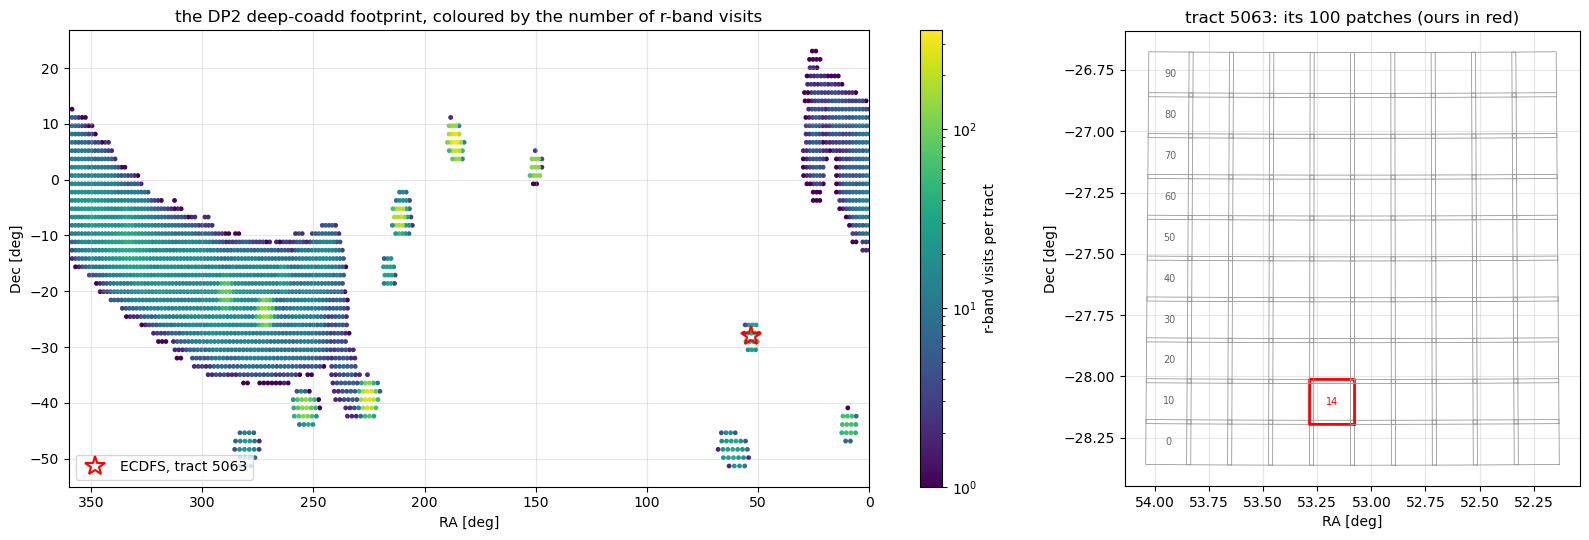

In [2]:
point = geom.SpherePoint(RA * geom.degrees, DEC * geom.degrees)
tract_info = skymap.findTract(point)
TRACT = tract_info.getId()
PATCH = tract_info.findPatch(point).getSequentialIndex()
print(f'(RA, Dec) = ({RA}, {DEC}) is in tract {TRACT}, patch {PATCH}')

tracts = sorted({d['tract'] for d in butler.registry.queryDataIds(['tract'], datasets='deep_coadd',
                                                                    where=f"band = '{BAND}'", skymap=SKYMAP)})
centres = np.array([[skymap[t].getCtrCoord().getRa().asDegrees(), skymap[t].getCtrCoord().getDec().asDegrees()]
                    for t in tracts])
inputs = butler.get('deep_coadd_input_summary', skymap=SKYMAP, parameters={'columns': ['tract', 'visit', 'band']}).to_pandas()
n_visits = inputs[inputs.band == BAND].groupby('tract').visit.nunique().reindex(tracts)   # distinct visits in each tract's coadds
del inputs                                                   # 21 million rows: free the memory
print(f'{len(tracts)} tracts have an {BAND}-band deep coadd, made from {n_visits.min():.0f} to {n_visits.max():.0f} {BAND}-band visits '
      f'(median {n_visits.median():.0f}); tract {TRACT} has {n_visits[TRACT]:.0f}')
patch_records = {r.id: r for r in butler.registry.queryDimensionRecords('patch', where=f'tract = {TRACT}', skymap=SKYMAP)}


def outline(region):
    # (RA, Dec) of the corners of a sky polygon, closed
    v = [LonLat(p) for p in region.getVertices()]
    ra, dec = [x.getLon().asDegrees() for x in v], [x.getLat().asDegrees() for x in v]
    return ra + ra[:1], dec + dec[:1]


fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw=dict(width_ratios=[2.2, 1]))
sc = axes[0].scatter(centres[:, 0], centres[:, 1], s=6, c=n_visits.values, cmap='viridis', norm=LogNorm(vmin=1, vmax=n_visits.max()))
plt.colorbar(sc, ax=axes[0], label=f'{BAND}-band visits per tract')
axes[0].plot(RA, DEC, 'r*', ms=15, mfc='none', mew=1.5, label=f'ECDFS, tract {TRACT}')
axes[0].set_xlim(360, 0); axes[0].set_xlabel('RA [deg]'); axes[0].set_ylabel('Dec [deg]'); axes[0].legend(loc='lower left')
axes[0].set_title(f'the DP2 deep-coadd footprint, coloured by the number of {BAND}-band visits')
for pid, rec in patch_records.items():
    ra, dec = outline(rec.region)
    axes[1].plot(ra, dec, c='r' if pid == PATCH else '0.6', lw=2 if pid == PATCH else 0.6)
    if pid % 10 == 0 or pid == PATCH:
        axes[1].text(np.mean(ra[:4]), np.mean(dec[:4]), pid, ha='center', va='center', fontsize=7,
                     color='r' if pid == PATCH else '0.4')
axes[1].invert_xaxis(); axes[1].set_aspect(1 / np.cos(np.radians(DEC)))
axes[1].set_xlabel('RA [deg]'); axes[1].set_ylabel('Dec [deg]'); axes[1].set_title(f'tract {TRACT}: its 100 patches (ours in red)')
plt.tight_layout(); plt.show()

### Questions

1. Neighbouring patches overlap. Why would a coadd pipeline want that?

## 2. The images and the PSF

A `deep_coadd` is one band of one patch. In DP2 it is a `CellCoadd` from the new `lsst.images` data model: an image in nJy, a mask and a variance plane, the PSF model and the sky projection (WCS). We load the g, r and i coadds of our patch.

In [3]:
coadds = {band: butler.get('deep_coadd', band=band, tract=TRACT, patch=PATCH, skymap=SKYMAP) for band in 'gri'}
coadd = coadds[BAND]
bbox = coadd.bbox
X0, Y0 = bbox.x.start, bbox.y.start                       # the patch in tract pixel coordinates
EXTENT = [bbox.x.start, bbox.x.stop, bbox.y.start, bbox.y.stop]
noise = 1.4826 * np.nanmedian(np.abs(coadd.image.array - np.nanmedian(coadd.image.array)))
print(f'{BAND}-band coadd of tract {TRACT}, patch {PATCH}: {coadd.image.array.shape[1]} x {coadd.image.array.shape[0]} pixels, '
      f'x = {bbox.x.start}...{bbox.x.stop}, y = {bbox.y.start}...{bbox.y.stop} (tract pixels), in {coadd.unit}')
print(f'noise per pixel: {noise:.2f} nJy (robust scatter of the image), {np.sqrt(np.nanmedian(coadd.variance.array)):.2f} nJy '
      '(from the variance plane)')

r-band coadd of tract 5063, patch 14: 3300 x 3300 pixels, x = 11850...15150, y = 2850...6150 (tract pixels), in nJy
noise per pixel: 5.06 nJy (robust scatter of the image), 4.38 nJy (from the variance plane)


The tract's pixel grid has north up and east to the left: $+x$ points west (decreasing RA), $+y$ north. All positions below are in these tract pixels (0.2″ each). We show the whole patch, and a zoom in colour (g, r, i).

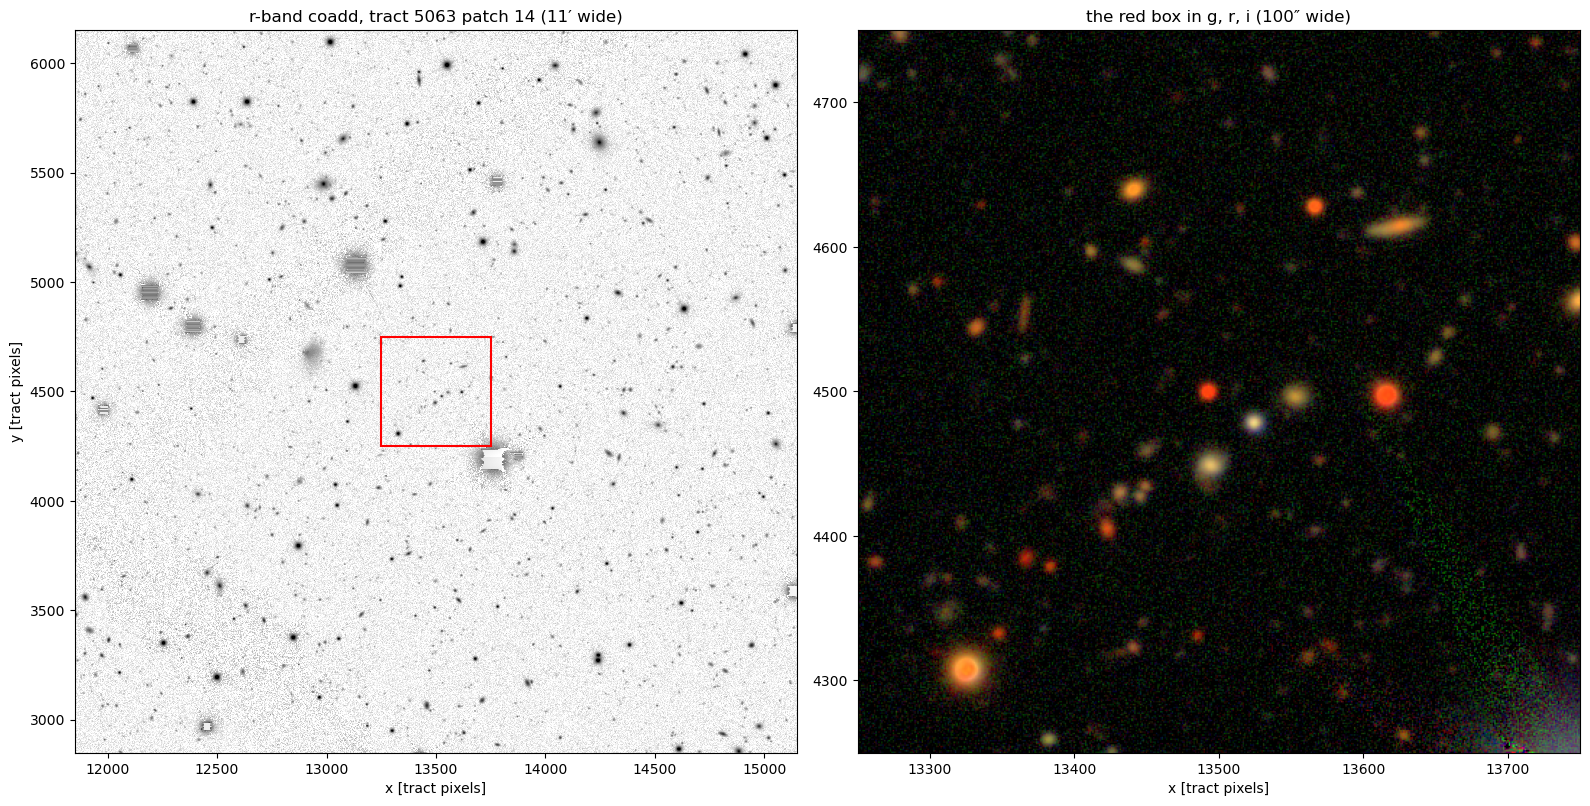

In [4]:
def show(ax, array, extent, title='', soft=10.0, vmax=6):
    # asinh stretch: linear below `soft` nJy, logarithmic above
    ax.imshow(np.arcsinh(array / soft), origin='lower', cmap='gray_r', vmin=-0.3, vmax=vmax, extent=extent,
              interpolation='none')
    ax.set_title(title); ax.set_xlabel('x [tract pixels]'); ax.set_ylabel('y [tract pixels]'); ax.grid(False)


ZOOM = (13250, 4250, 500)                                 # x, y of the lower-left corner, and size, in tract pixels
zx, zy, zs = ZOOM
zsl = np.s_[zy - Y0:zy - Y0 + zs, zx - X0:zx - X0 + zs]
zext = [zx, zx + zs, zy, zy + zs]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
show(axes[0], coadd.image.array, EXTENT, f'{BAND}-band coadd, tract {TRACT} patch {PATCH} ({3300 * PIXEL_SCALE / 60:.0f}′ wide)')
axes[0].add_patch(plt.Rectangle((zx, zy), zs, zs, fill=False, ec='r', lw=1.5))
rgb = make_lupton_rgb(*(coadds[b].image.array[zsl] for b in 'irg'), stretch=40, Q=8)
axes[1].imshow(rgb, origin='lower', extent=zext); axes[1].grid(False)
axes[1].set_title(f'the red box in g, r, i ({zs * PIXEL_SCALE:.0f}″ wide)'); axes[1].set_xlabel('x [tract pixels]')
plt.tight_layout(); plt.show()

### The PSF

The PSF model can be evaluated anywhere in the coadd. In a cell-based coadd, each 30″ cell has its own PSF, made from the visits that cover that cell. We measure its size and shape with GalSim's HSM adaptive moments, at the patch centre and then at the centre of every cell. HSM's `observed_shape` is a `galsim.Shear`; we use its reduced-shear components $g_1, g_2$.

PSF at the patch centre: FWHM 1.01", g1 = +0.0118, g2 = -0.0007
across the 22 x 22 cells: FWHM 0.85" to 1.10", |g| up to 0.046


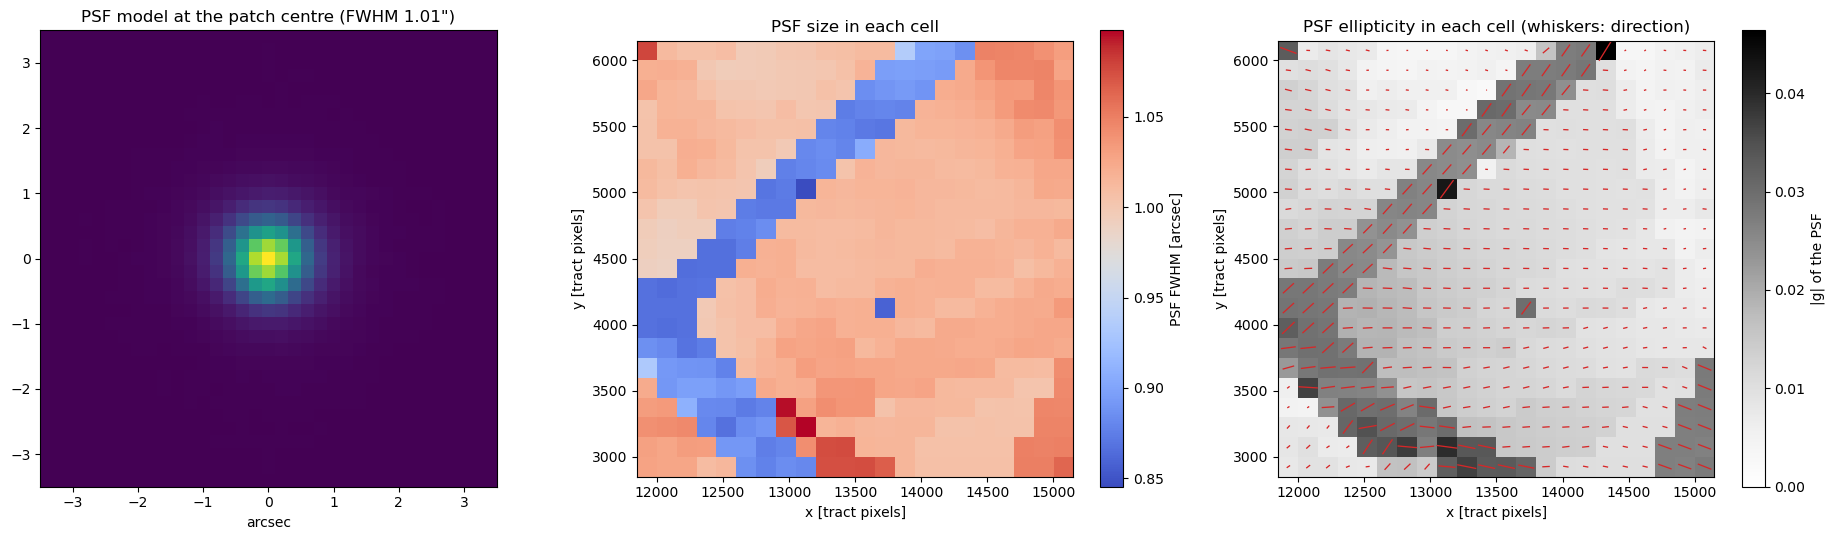

In [5]:
def psf_moments(x, y):
    # HSM size (sigma, pixels) and shape (g1, g2) of the PSF model at tract pixel (x, y)
    k = coadd.psf.compute_kernel_image(x=x, y=y)
    res = galsim.hsm.FindAdaptiveMom(galsim.Image(np.ascontiguousarray(k.array), scale=1.0))
    return res.moments_sigma, res.observed_shape.g1, res.observed_shape.g2, k.array


xc, yc = (bbox.x.start + bbox.x.stop) / 2, (bbox.y.start + bbox.y.stop) / 2
s0, g10, g20, kern = psf_moments(xc, yc)
PSF_FWHM = s0 * SIGMA_TO_FWHM * PIXEL_SCALE
print(f'PSF at the patch centre: FWHM {PSF_FWHM:.2f}", g1 = {g10:+.4f}, g2 = {g20:+.4f}')

CELL = 150                                                  # cell size, pixels
cx = np.arange(bbox.x.start + CELL / 2, bbox.x.stop, CELL)
cy = np.arange(bbox.y.start + CELL / 2, bbox.y.stop, CELL)
gx, gy = np.meshgrid(cx, cy)
pm = np.array([psf_moments(x, y)[:3] for x, y in zip(gx.ravel(), gy.ravel())]).reshape(len(cy), len(cx), 3)
fwhm = pm[..., 0] * SIGMA_TO_FWHM * PIXEL_SCALE
g_abs, angle = np.hypot(pm[..., 1], pm[..., 2]), 0.5 * np.arctan2(pm[..., 2], pm[..., 1])
print(f'across the {len(cx)} x {len(cy)} cells: FWHM {fwhm.min():.2f}" to {fwhm.max():.2f}", |g| up to {g_abs.max():.3f}')

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
n = kern.shape[0]
axes[0].imshow(kern, origin='lower', cmap='viridis', extent=np.array([-n, n, -n, n]) / 2 * PIXEL_SCALE)
axes[0].set_title(f'PSF model at the patch centre (FWHM {PSF_FWHM:.2f}")'); axes[0].set_xlabel('arcsec'); axes[0].grid(False)
im = axes[1].imshow(fwhm, origin='lower', extent=EXTENT, cmap='coolwarm')
plt.colorbar(im, ax=axes[1], label='PSF FWHM [arcsec]'); axes[1].set_title('PSF size in each cell')
im = axes[2].imshow(g_abs, origin='lower', extent=EXTENT, cmap='Greys', vmin=0)
plt.colorbar(im, ax=axes[2], label='|g| of the PSF'); axes[2].set_title('PSF ellipticity in each cell (whiskers: direction)')
L = 4000                                                    # whisker length per unit g, in pixels
axes[2].quiver(gx, gy, L * g_abs * np.cos(angle), L * g_abs * np.sin(angle), angles='xy', scale_units='xy', scale=1,
               headwidth=0, headlength=0, headaxislength=0, pivot='middle', width=0.003, color='tab:red')
for ax in axes[1:]:
    ax.set_xlabel('x [tract pixels]'); ax.set_ylabel('y [tract pixels]'); ax.grid(False)
plt.tight_layout(); plt.show()

### Why the PSF changes from cell to cell

The jumps in the PSF maps follow straight lines. To find out why, we look at the coadd's **provenance**. `coadd.provenance.inputs` lists every input image (one detector of one visit), with its outline on our patch. `coadd.provenance.contributions` lists, for every cell, the images added there, each with its weight and the second moments of its PSF model at the cell. Every contribution covers its whole cell (`overlap_fraction` is always 1): a cell-based coadd adds an image to a cell only if the image covers all of it.

A coadd's PSF is the weighted sum of its inputs' PSFs, so the PSF of a cell depends on which images it holds, and on their weights. We map three properties of the cells: the number of input images, the noise per pixel, and, for each night, the share of the cell's weight that comes from that night's visits. In each night's panel, the red lines outline the detectors of that night's first visit, from `coadd.provenance.inputs`: where two lines run close and parallel, there is a gap between two detectors.

90 input images from 31 visits on 7 nights; overlap_fraction is always 1: True


,visits,weight_per_image,weight_share,fwhm_mean,fwhm_scatter,fwhm_min,fwhm_max,e_mean,angle_spread
night,,,,,,,,,
20250728,6,0.0042,0.526,1.20,0.07,1.11,1.30,0.086,18.0
20250813,6,0.0011,0.148,0.81,0.05,0.77,0.90,0.102,30.0
20250906,9,0.0002,0.043,1.48,0.09,1.37,1.67,0.100,8.0
20251104,2,0.0004,0.018,0.99,0.16,0.87,1.10,0.053,30.0
20251108,1,0.0027,0.057,0.93,NaN,0.93,0.93,0.153,NaN
20251122,1,0.0036,0.006,1.00,NaN,1.00,1.00,0.179,NaN
20260105,6,0.0014,0.202,0.87,0.03,0.85,0.91,0.153,3.0


correlation of the PSF FWHM with the number of input images: +0.66
correlation of the PSF FWHM with the weight share of night 20250728: +0.98
correlation of the PSF FWHM with the noise per pixel: -0.85
83 cells have less than 20% of their weight from night 20250728: FWHM 0.88" (other cells 1.01"), |g| 0.027 (0.010), noise 6.5 nJy (4.3 nJy)


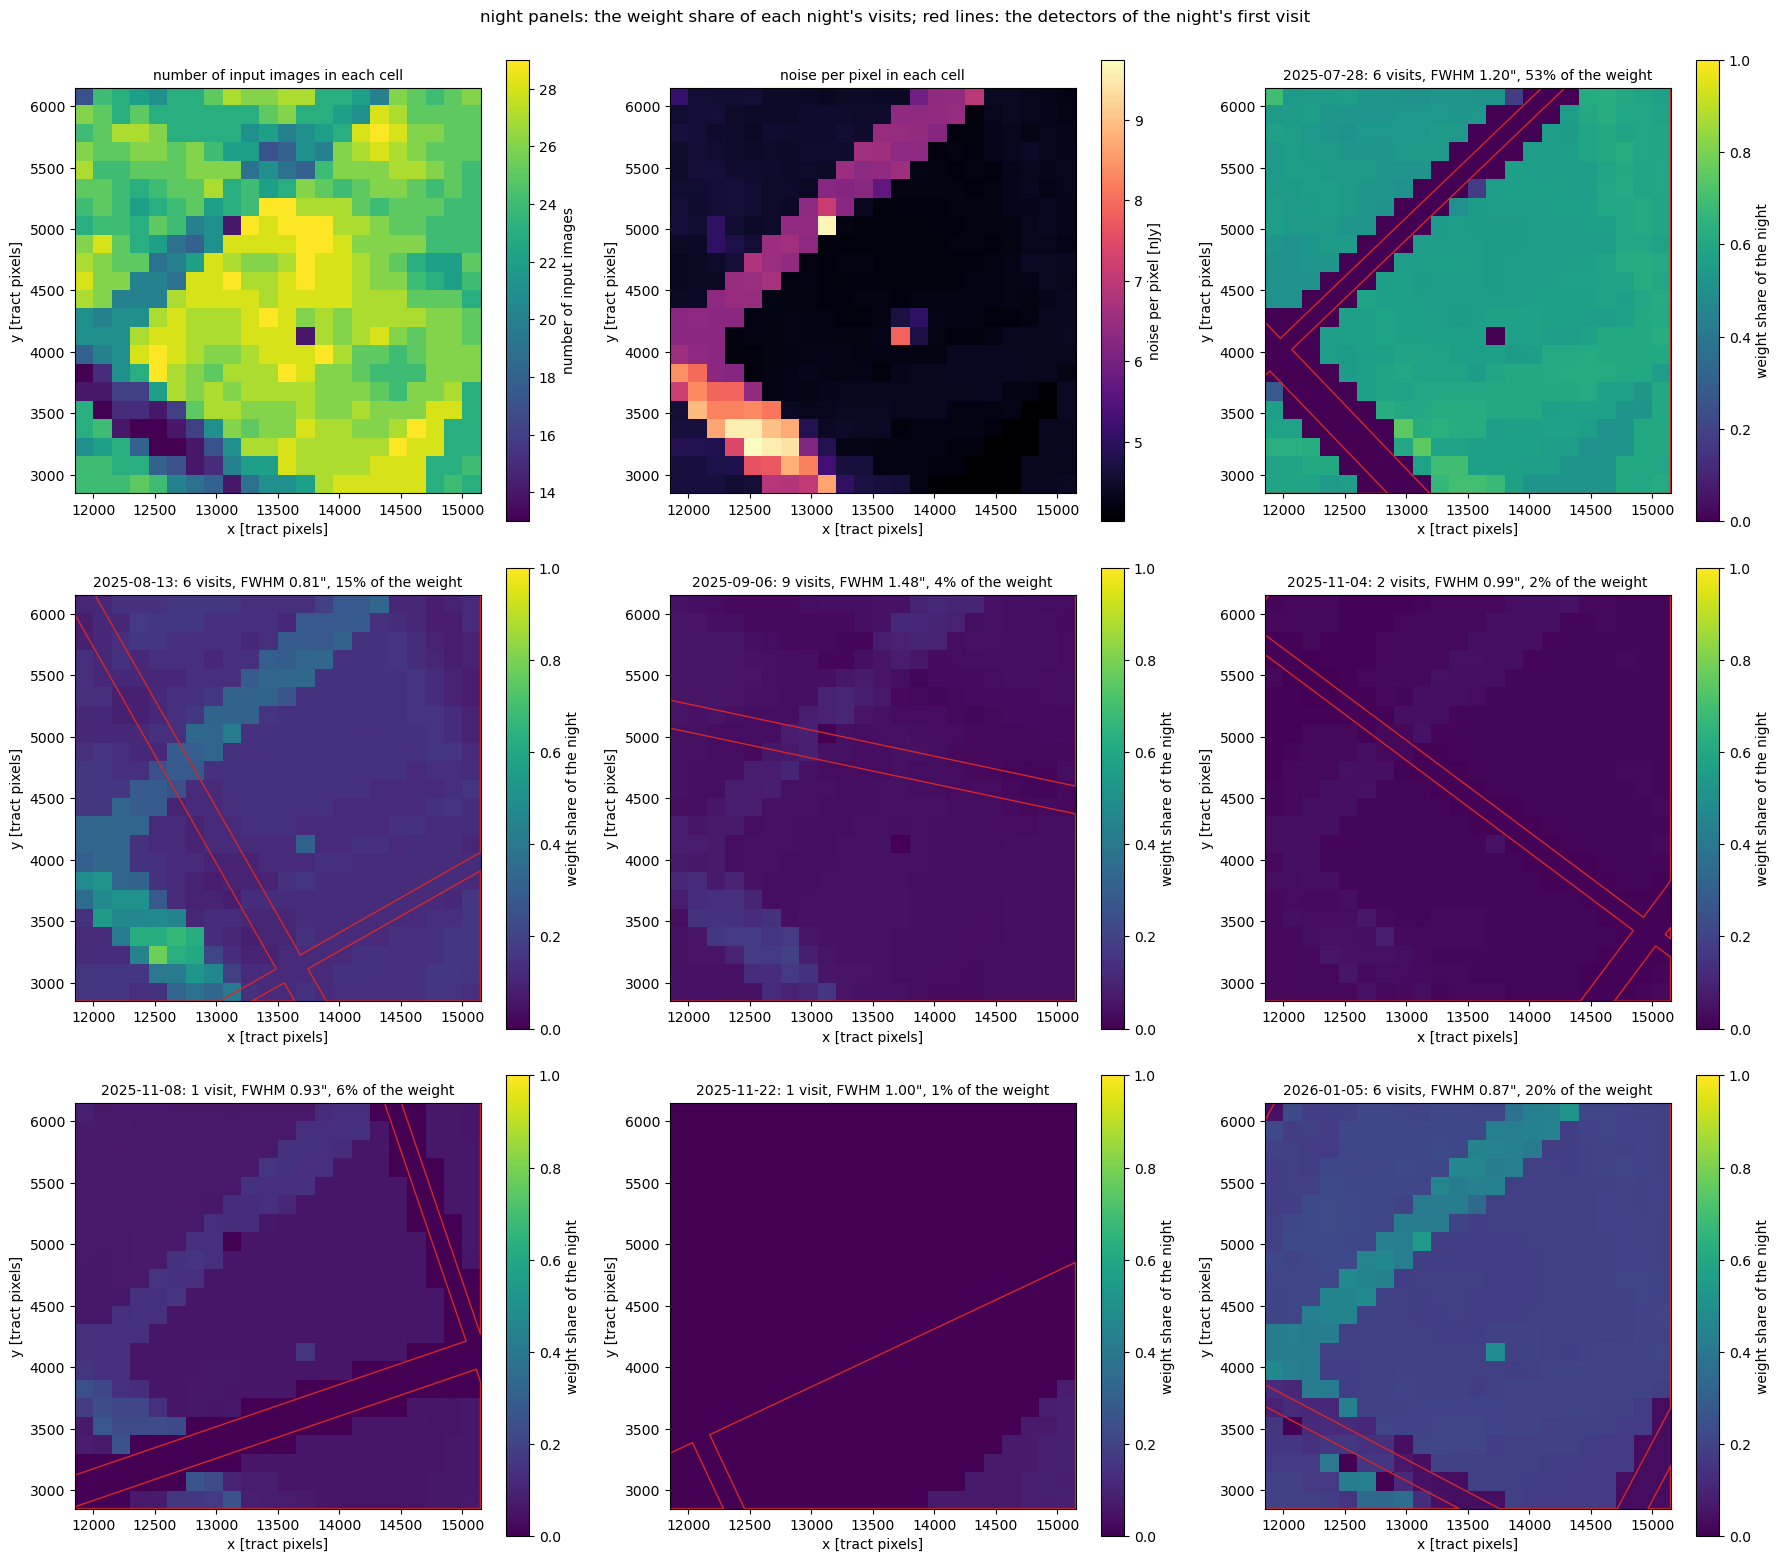

In [6]:
inputs = coadd.provenance.inputs                            # one row per input image (one detector of one visit)
contrib = coadd.provenance.contributions.to_pandas()        # one row per cell and input image; cell_i is the row, cell_j the column
contrib['night'] = contrib.visit // 100000                  # a visit ID is the night (day_obs) x 100000 + a sequence number
contrib['T'] = contrib.psf_shape_xx + contrib.psf_shape_yy  # trace of the input PSF's moments, pixels^2
contrib['fwhm'] = np.sqrt(contrib['T'] / 2) * SIGMA_TO_FWHM * PIXEL_SCALE
print(f'{len(inputs)} input images from {contrib.visit.nunique()} visits on {contrib.night.nunique()} nights; '
      f'overlap_fraction is always 1: {(contrib.overlap_fraction == 1).all()}')

contrib['e1'] = (contrib.psf_shape_xx - contrib.psf_shape_yy) / contrib['T']   # distortion of each input PSF
contrib['e2'] = 2 * contrib.psf_shape_xy / contrib['T']
visits = contrib.groupby(['night', 'visit']).agg(fwhm=('fwhm', 'median'), e1=('e1', 'median'), e2=('e2', 'median'))   # over the patch
visits['e'] = np.hypot(visits.e1, visits.e2)
visits['angle'] = np.degrees(0.5 * np.arctan2(visits.e2, visits.e1)) % 180     # direction of the elongation, degrees from +x


def angle_spread(a):
    # scatter of directions defined modulo 180 degrees, in degrees (NaN for a single visit)
    if len(a) < 2:
        return np.nan
    z = np.exp(2j * np.radians(np.asarray(a))).mean()
    return np.degrees(0.5 * np.sqrt(-2 * np.log(abs(z))))


per_visit = visits.groupby(level='night').agg(fwhm_mean=('fwhm', 'mean'), fwhm_scatter=('fwhm', 'std'), fwhm_min=('fwhm', 'min'),
                                              fwhm_max=('fwhm', 'max'), e_mean=('e', 'mean'), angle_spread=('angle', angle_spread))
nights = contrib.groupby('night').agg(visits=('visit', 'nunique'), weight_per_image=('weight', 'median'),
                                      weight_share=('weight', 'sum')).join(per_visit)
nights['weight_share'] /= nights.weight_share.sum()
HEAVY = nights.weight_share.idxmax()                        # the night that carries the most weight
display(nights.round({'weight_per_image': 4, 'weight_share': 3, 'fwhm_mean': 2, 'fwhm_scatter': 2, 'fwhm_min': 2,
                      'fwhm_max': 2, 'e_mean': 3, 'angle_spread': 0}))


def cell_map(values):
    # a Series indexed by (cell_i, cell_j), as a 2D array like `fwhm`
    out = np.full(fwhm.shape, np.nan)
    out[values.index.get_level_values('cell_i'), values.index.get_level_values('cell_j')] = values.values
    return out


by_cell = contrib.groupby(['cell_i', 'cell_j'])
w_cell = by_cell.weight.sum()
n_inputs = cell_map(by_cell.size())
share = {n: cell_map(contrib.weight.where(contrib.night == n, 0).groupby([contrib.cell_i, contrib.cell_j]).sum() / w_cell)
         for n in nights.index}                             # for each night, the share of each cell's weight from its visits
heavy_share = share[HEAVY]
noise_cell = np.sqrt(np.nanmedian(coadd.variance.array.reshape(len(cy), CELL, len(cx), CELL), axis=(1, 3)))
for name, m in [('the number of input images', n_inputs), (f'the weight share of night {HEAVY}', heavy_share),
                ('the noise per pixel', noise_cell)]:
    print(f'correlation of the PSF FWHM with {name}: {np.corrcoef(fwhm.ravel(), m.ravel())[0, 1]:+.2f}')
gaps = heavy_share < 0.2
print(f'{gaps.sum()} cells have less than 20% of their weight from night {HEAVY}: FWHM {np.median(fwhm[gaps]):.2f}" '
      f'(other cells {np.median(fwhm[~gaps]):.2f}"), |g| {np.median(g_abs[gaps]):.3f} ({np.median(g_abs[~gaps]):.3f}), '
      f'noise {np.median(noise_cell[gaps]):.1f} nJy ({np.median(noise_cell[~gaps]):.1f} nJy)')

date = lambda n: f'{str(n)[:4]}-{str(n)[4:6]}-{str(n)[6:]}'
panels = [(n_inputs, 'number of input images in each cell', 'number of input images', dict(cmap='viridis')),
          (noise_cell, 'noise per pixel in each cell', 'noise per pixel [nJy]', dict(cmap='magma'))]
panels += [(share[n], f'{date(n)}: {nights.visits[n]} visit{"s" if nights.visits[n] > 1 else ""}, FWHM {nights.fwhm_mean[n]:.2f}", {100 * nights.weight_share[n]:.0f}% of the weight',
            'weight share of the night', dict(cmap='viridis', vmin=0, vmax=1)) for n in nights.index]
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
for ax, (m, title, label, kw) in zip(axes.ravel(), panels):
    im = ax.imshow(m, origin='lower', extent=EXTENT, **kw)
    plt.colorbar(im, ax=ax, label=label); ax.set_title(title, fontsize=10)
    ax.set_xlabel('x [tract pixels]'); ax.set_ylabel('y [tract pixels]'); ax.grid(False)
for ax, n in zip(axes.ravel()[2:], nights.index):          # red: the detector outlines of the night's first visit
    first = min(v for v in inputs['visit'] if v // 100000 == n)
    for row in inputs[inputs['visit'] == first]:
        xs, ys = np.asarray(row['polygon'].x_vertices), np.asarray(row['polygon'].y_vertices)
        ax.plot(np.append(xs, xs[0]), np.append(ys, ys[0]), c='tab:red', lw=1)
    ax.set_xlim(EXTENT[:2]); ax.set_ylim(EXTENT[2:])
for ax in axes.ravel()[len(panels):]:
    ax.set_visible(False)
fig.suptitle("night panels: the weight share of each night's visits; red lines: the detectors of the night's first visit", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.98]); plt.show()

**What the provenance shows.** The PSF of each cell is the weighted sum of its inputs' PSFs, so the jumps come from which images each cell holds.

- **Visits of one night are similar, not identical.** On the nights with six or more visits, their FWHM scatters by only 0.03–0.09″ (the `fwhm_scatter` column), against a range of 0.77–1.67″ between nights: the night sets the seeing, but the atmosphere changes from one 30 s visit to the next. The direction of the elongation changes more (`angle_spread`): by 18–30° on 2025-07-28, 2025-08-13 and 2025-11-04, by 8° on 2025-09-06, and by only 3° on 2026-01-05, when all six visits were elongated in the same direction.
- **The weights ignore the seeing.** A weight is the inverse of an image's noise variance, set mostly by the sky brightness and the transparency. Every visit is 30 s long, yet the six visits of 2025-07-28, with a seeing of 1.1–1.3″, each have four times the weight of the 0.8″ visits of 2025-08-13. Together they carry half of the patch's weight.
- **They share their detector gaps.** The six visits were taken one after another, with dithers of less than 1″. The cells along the gaps between their detectors 97, 98 and 136 lose them (the panel of 2025-07-28). The gaps run diagonally because the camera was rotated with respect to the tract that night.
- **Along the gaps**, the sharper visits of August and January dominate (the panels of 2025-08-13 and 2026-01-05). The PSF there is sharper, and more elongated: the January visits are all elongated in one direction, which the July visits partly cancel elsewhere. The noise is higher, because those cells lost their heaviest inputs (second panel).

A few other cells jump for the same reason: some visits are missing there too. You can list them with `contrib`.

### Questions

1. The PSF here is about 1″ wide and elongated by a few percent. What does a larger PSF do to the galaxies whose shapes we can measure? Why does a few-percent elongation matter for a shear signal of a percent or less?
2. Along the detector gaps the PSF is sharper, but the noise is higher. Which would you rather have for measuring shapes? What would weighting each image by its seeing, as well as by its noise, do to the coadd?
3. The six visits of the heaviest night share their detector gaps because they were barely dithered. How would larger dithers have helped? Why does a cell-based coadd leave an image out of a cell that it only partly covers, rather than use the part it covers? (Think of the PSF where the set of input images changes in the middle of a cell.)

## 3. Detecting objects

`SourceDetectionTask` first smooths the image with a **kernel**: each pixel is replaced by an average of its neighbours, weighted by a circular Gaussian as wide as the PSF (σ = 2.15 px = 0.43″ here). Averaging over about 60 pixels lowers the noise about 8 times, much more than it lowers the light of an object, which is never narrower than the PSF, so faint objects stand out. For a point source this is close to the optimal filter. The task then marks every pixel of this **kernel-smoothed image** above a threshold, in units of its noise. Each connected group of such pixels is a **footprint**, and the local maxima of the smoothed image inside it are its **peaks**. The footprints are then grown by 1″, and footprints that touch merge into one. The smoothed image only decides which pixels belong to a footprint and where the peaks are: the figures show the original coadd, and deblending and measurement use its original pixels. The coadd is already background-subtracted, so we turn off the task's own background estimate.

The tasks work on the pipelines' `afw` image types, so we first convert the `CellCoadd` with `to_legacy()`. We also set up the deblending and measurement tasks of Sections 4 and 5 now, because each task adds its columns to a shared **schema**, and the catalogue must be made from the complete schema.

In [7]:
exposure = coadd.to_legacy()                 # an lsst.afw.image.ExposureF, with the same PSF, WCS and mask
schema = afwTable.SourceTable.makeMinimalSchema()

det_config = SourceDetectionTask.ConfigClass()
det_config.thresholdValue = 5.0              # in units of the noise
det_config.reEstimateBackground = False
detection_task = SourceDetectionTask(schema=schema, config=det_config)

deblend_task = SourceDeblendTask(schema=schema)

meas_config = SingleFrameMeasurementTask.ConfigClass()
meas_config.plugins.names = ['base_SdssCentroid', 'base_PixelFlags', 'base_PsfFlux', 'base_GaussianFlux',
                             'ext_shapeHSM_HsmSourceMoments',   # adaptive moments of the object
                             'ext_shapeHSM_HsmPsfMoments',      # adaptive moments of the PSF model at its position
                             'ext_shapeHSM_HsmShapeRegauss']    # PSF-corrected shape: e1, e2, resolution
meas_config.slots.apFlux = None; meas_config.slots.calibFlux = None
meas_config.slots.modelFlux = 'base_GaussianFlux'; meas_config.slots.gaussianFlux = 'base_GaussianFlux'
meas_config.slots.shape = 'ext_shapeHSM_HsmSourceMoments'; meas_config.slots.psfShape = 'ext_shapeHSM_HsmPsfMoments'
measure_task = SingleFrameMeasurementTask(schema=schema, config=meas_config)

sources = detection_task.run(afwTable.SourceTable.make(schema), exposure).sources
area = (3300 * PIXEL_SCALE / 60)**2                         # arcmin2
n_peaks = np.array([len(s.getFootprint().getPeaks()) for s in sources])
print(f'{len(sources)} footprints ({len(sources) / area:.0f} per arcmin2); {(n_peaks > 1).sum()} of them have more than one peak')

3922 footprints (32 per arcmin2); 1063 of them have more than one peak


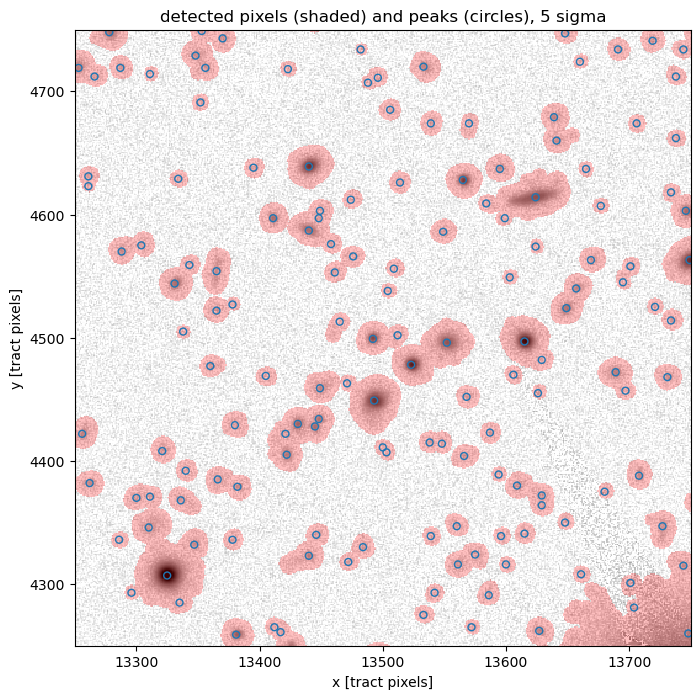

In [8]:
def zoom_overlay(ax, cat_x, cat_y, title, **kw):
    show(ax, coadd.image.array[zsl], zext, title)
    det = (exposure.mask.array[zsl] & exposure.mask.getPlaneBitMask('DETECTED')) > 0
    ax.imshow(np.ma.masked_where(~det, det), origin='lower', extent=zext, cmap='autumn', alpha=0.25, interpolation='none')
    inside = (cat_x > zx) & (cat_x < zx + zs) & (cat_y > zy) & (cat_y < zy + zs)
    ax.scatter(cat_x[inside], cat_y[inside], **kw)
    ax.set_xlim(zext[:2]); ax.set_ylim(zext[2:])


px = np.array([p.getFx() for s in sources for p in s.getFootprint().getPeaks()])
py = np.array([p.getFy() for s in sources for p in s.getFootprint().getPeaks()])
fig, ax = plt.subplots(figsize=(8, 8))
zoom_overlay(ax, px, py, 'detected pixels (shaded) and peaks (circles), 5 sigma', s=25, facecolor='none', edgecolor='tab:blue')
plt.show()

### Questions

1. Some footprints contain several peaks. Are they all real blends of separate objects, or can one large galaxy have several peaks?

## 4. Deblending

A footprint with several peaks is a **parent**. `SourceDeblendTask` (the deblender of SDSS, kept in the pipelines as `meas_deblender`) builds a template for each peak, assuming each child is symmetric about its peak, and shares out the parent's flux among the children. Each child gets a *heavy footprint*: its own deblended pixels. DP2's own processing deblends all bands together with *scarlet*, a more sophisticated method.

After deblending, the catalogue holds the parents and their children. For measurement we keep every object that has not been split: the children, and the parents with a single peak.

The figure below shows a blended parent from the zoom: the parent, the deblended pixels of each child (its peak marked by a cross), and the parent minus the sum of its children. Each child's title gives the **significance** of its peak: its value in the kernel-smoothed image of Section 3, in units of that image's noise. Every peak is above the 5σ detection threshold.

In [9]:
deblend_task.run(exposure, sources)
sources = sources.copy(deep=True)            # contiguous in memory, which column access needs
n_child, parent_id = sources['deblend_nChild'], sources['parent']
print(f'{len(sources)} records: {(n_child > 0).sum()} parents split into {(parent_id > 0).sum()} children, '
      f'{((n_child == 0) & (parent_id == 0)).sum()} isolated objects')
print(f'{((n_child == 0)).sum() / area:.0f} objects per arcmin2 after deblending')

6982 records: 1051 parents split into 3060 children, 2871 isolated objects
49 objects per arcmin2 after deblending


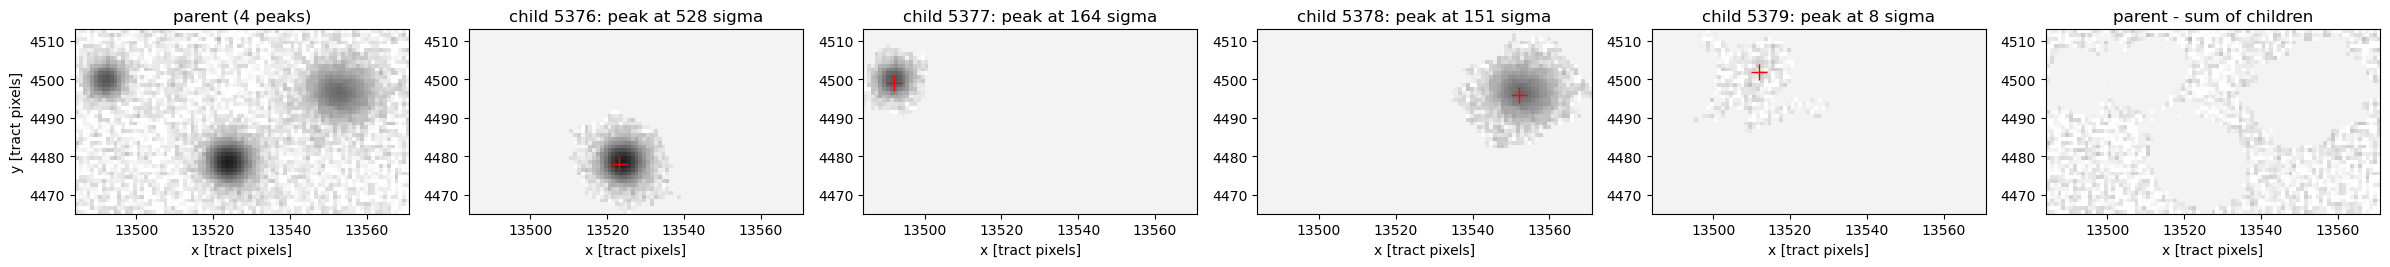

In [10]:
## a blended parent in the zoom, and its children
peak_xy = np.array([[s.getFootprint().getPeaks()[0].getFx(), s.getFootprint().getPeaks()[0].getFy()] for s in sources])
in_zoom = (peak_xy[:, 0] > zx) & (peak_xy[:, 0] < zx + zs) & (peak_xy[:, 1] > zy) & (peak_xy[:, 1] < zy + zs)
flux_peak = np.array([s.getFootprint().getPeaks()[0].getPeakValue() for s in sources])
cand = np.where(in_zoom & (n_child >= 2) & (n_child <= 4))[0]
par = sources[int(cand[np.argmax(flux_peak[cand])])]
kids = [s for s in sources if s.getParent() == par.getId()]
pb = par.getFootprint().getBBox()
pext = [pb.getMinX(), pb.getMaxX() + 1, pb.getMinY(), pb.getMaxY() + 1]

fig, axes = plt.subplots(1, len(kids) + 2, figsize=(4 * (len(kids) + 2), 4))
parent_img = exposure.image[pb].array
vmax = np.arcsinh(parent_img.max() / 5)
show(axes[0], parent_img, pext, f'parent ({len(kids)} peaks)', vmax=vmax)
model = np.zeros_like(parent_img)
for ax, kid in zip(axes[1:], kids):
    im = afwImage.ImageF(pb); kid.getFootprint().insert(im); model += im.array
    significance = kid.getFootprint().getPeaks()[0]['significance']      # in the kernel-smoothed image, in units of its noise
    show(ax, im.array, pext, f'child {kid.getId()}: peak at {significance:.0f} sigma', vmax=vmax)
    ax.plot(kid.getFootprint().getPeaks()[0].getFx(), kid.getFootprint().getPeaks()[0].getFy(), 'r+', ms=12)
show(axes[-1], parent_img - model, pext, 'parent - sum of children', vmax=vmax)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.tight_layout(); plt.show()

### Questions

1. Is child 5379 a real object, or a noise peak that the deblender turned into a child? What in the figure argues each way, and how could you check?

## 5. Measuring shapes

`SingleFrameMeasurementTask` runs the measurement plugins on every object. When it measures a child, it replaces the other objects with noise, so that each object is measured on its own deblended pixels. The plugins (set up in Section 3):

| plugin | what it measures |
|---|---|
| `base_SdssCentroid` | the centroid |
| `base_PixelFlags` | flags for edges, saturation, missing data, ... |
| `base_PsfFlux`, `base_GaussianFlux` | fluxes (nJy): with the PSF, and with an elliptical Gaussian matched to the object |
| `ext_shapeHSM_HsmSourceMoments` | the adaptive moments $I_{xx}, I_{yy}, I_{xy}$ of the object, PSF included |
| `ext_shapeHSM_HsmPsfMoments` | the same moments of the PSF model at the object's position |
| `ext_shapeHSM_HsmShapeRegauss` | the PSF-corrected distortion $e_1, e_2$ (re-Gaussianization), its error, and the resolution $R_2$ |

In [11]:
measure_task.run(measCat=sources, exposure=exposure)
raw = sources.asAstropy().to_pandas()
raw = raw[raw.deblend_nChild == 0]                         # children and isolated objects

wcs = exposure.getWcs()
sky = [wcs.pixelToSky(x, y) for x, y in zip(raw.slot_Centroid_x, raw.slot_Centroid_y)]
M, P, S = 'ext_shapeHSM_HsmSourceMoments_', 'ext_shapeHSM_HsmPsfMoments_', 'ext_shapeHSM_HsmShapeRegauss_'
flux, flux_err = raw.base_GaussianFlux_instFlux, raw.base_GaussianFlux_instFluxErr
with np.errstate(divide='ignore', invalid='ignore'):
    T = raw[M + 'xx'] + raw[M + 'yy']
    T_psf = raw[P + 'xx'] + raw[P + 'yy']
    cat = pd.DataFrame(dict(
        x=raw.slot_Centroid_x, y=raw.slot_Centroid_y,
        ra=[s.getRa().asDegrees() for s in sky], dec=[s.getDec().asDegrees() for s in sky],
        is_child=raw.parent > 0,
        mag=np.where(flux > 0, ZP_NJY - 2.5 * np.log10(flux), np.nan), snr=flux / flux_err,
        sigma_obs=np.sqrt(T / 2) * PIXEL_SCALE,               # Gaussian sigma of the moments, arcsec (PSF included)
        T_ratio=T / T_psf,                                     # 1 for a point source
        e1_obs=(raw[M + 'xx'] - raw[M + 'yy']) / T, e2_obs=2 * raw[M + 'xy'] / T,           # moments, PSF included
        e1_psf=(raw[P + 'xx'] - raw[P + 'yy']) / T_psf, e2_psf=2 * raw[P + 'xy'] / T_psf,   # the PSF model there
        e1=raw[S + 'e1'], e2=raw[S + 'e2'], e_err=raw[S + 'sigma'], R2=raw[S + 'resolution'],
        good=~(raw.base_PixelFlags_flag_edge | raw.base_PixelFlags_flag_saturatedCenter | raw.base_PixelFlags_flag_bad
               | raw[M + 'flag'] | raw[P + 'flag'] | raw.base_GaussianFlux_flag),
        shape_ok=~raw[S + 'flag'],
    )).reset_index(drop=True)
print(f'{len(cat)} objects measured, {cat.good.sum()} without bad flags, {(cat.good & cat.shape_ok).sum()} with a regauss shape')
cat.head()

5931 objects measured, 4962 without bad flags, 4274 with a regauss shape


,x,y,ra,dec,is_child,mag,snr,sigma_obs,T_ratio,e1_obs,e2_obs,e1_psf,e2_psf,e1,e2,e_err,R2,good,shape_ok
0,11991.000000,2857.000000,53.277153,-28.195055,False,24.250619,16.824762,0.514545,1.387070,0.062943,-0.016996,0.005540,0.014385,0.201824,-0.106561,0.434066,0.237942,False,True
1,12061.942588,2870.873437,53.272681,-28.194290,False,NaN,NaN,NaN,NaN,NaN,NaN,0.004489,0.018153,NaN,NaN,NaN,NaN,False,False
2,12154.969055,2856.104621,53.266818,-28.195119,False,24.435503,14.576088,0.508257,1.360719,0.097634,0.059685,0.004206,0.018007,0.191844,0.119347,0.643810,0.241695,False,True
3,12468.000000,2858.000000,53.247088,-28.195038,False,24.065167,16.398976,0.667169,2.403203,-0.221023,0.249429,0.014632,0.004139,-0.460632,0.519319,0.196678,0.543519,False,True
4,12698.000000,2859.000000,53.232591,-28.194998,False,24.976371,6.917778,0.513850,1.863062,-0.145626,0.687053,-0.002882,0.032458,-0.285423,1.669332,0.559905,0.466768,False,True


**The distortion $e$.** The adaptive moments give the distortion of the object as observed, PSF included:

$$e_1 = \frac{I_{xx} - I_{yy}}{T}, \qquad e_2 = \frac{2 I_{xy}}{T}, \qquad T = I_{xx} + I_{yy}.$$

An ellipse with axis ratio $q$ has $|e| = (1 - q^2)/(1 + q^2)$: 0 if it is round, close to 1 if it is very thin. Adaptive moments are always those of an ellipse, $I_{xx} I_{yy} > I_{xy}^2$ (HSM fails otherwise), and this condition is the same as $|e| < 1$. So the observed distortion never reaches 1.

The PSF makes every object larger and rounder. If the galaxy and the PSF were both Gaussian, their moments would add, $I^{\rm obs} = I^{\rm gal} + I^{\rm PSF}$ for each of $I_{xx}$, $I_{yy}$ and $I_{xy}$. Solving for the galaxy gives

$$e^{\rm gal} = \frac{e^{\rm obs} - (1 - R_2)\, e^{\rm PSF}}{R_2}, \qquad R_2 = 1 - \frac{T^{\rm PSF}}{T^{\rm obs}},$$

where the resolution $R_2$ is the fraction of the observed size $T^{\rm obs}$ that belongs to the galaxy. Re-Gaussianization refines this. It first removes from the image the part of the PSF that isn't Gaussian, and its resolution factor allows for a galaxy profile that isn't Gaussian. Its last step is the same: subtract the PSF's part, and divide by the resolution.

The table below gives, in bins of $R_2$, the fraction of objects whose PSF-corrected distortion is larger than 1, and the errors that HSM reports for $e$.

In [12]:
ok = cat.good & cat.shape_ok
e_abs = np.hypot(cat.e1, cat.e2)
print(f'largest observed distortion |e_obs| (PSF included): {np.hypot(cat.e1_obs, cat.e2_obs)[ok].max():.3f}; '
      f'PSF-corrected |e| > 1 for {(e_abs[ok] > 1).mean():.0%} of the {ok.sum()} measured shapes')
by_R2 = pd.DataFrame({'R2 range': pd.cut(cat.R2[ok], [0, 0.1, 0.2, 0.3, 0.5, 1], right=False),
                      'large': e_abs[ok] > 1, 'error': cat.e_err[ok], 'error_x_R2': (cat.e_err * cat.R2)[ok]}).groupby('R2 range', observed=True)
pd.DataFrame({'objects': by_R2.size(), 'fraction with |e| > 1': by_R2.large.mean(),
              'median error on e': by_R2.error.median(), 'median error x R2': by_R2.error_x_R2.median()}).round(2)

largest observed distortion |e_obs| (PSF included): 0.965; PSF-corrected |e| > 1 for 36% of the 4274 measured shapes


,objects,fraction with |e| > 1,median error on e,median error x R2
R2 range,,,,
"[0.0, 0.1)",409,0.65,2.94,0.15
"[0.1, 0.2)",521,0.58,1.00,0.15
"[0.2, 0.3)",630,0.45,0.61,0.15
"[0.3, 0.5)",1421,0.33,0.36,0.14
"[0.5, 1.0)",1293,0.16,0.21,0.13


Not every measured shape is usable: for faint or barely resolved objects re-Gaussianization can return $|e| \gg 1$, and one object with $e = 50$ moves the mean of a thousand galaxies by 0.05. A **shape sample** needs cuts. We use those of the HSC first-year shape catalogue (Mandelbaum et al. 2018) in spirit: S/N > 10, $R_2 > 0.3$ and $|e| < 2$.

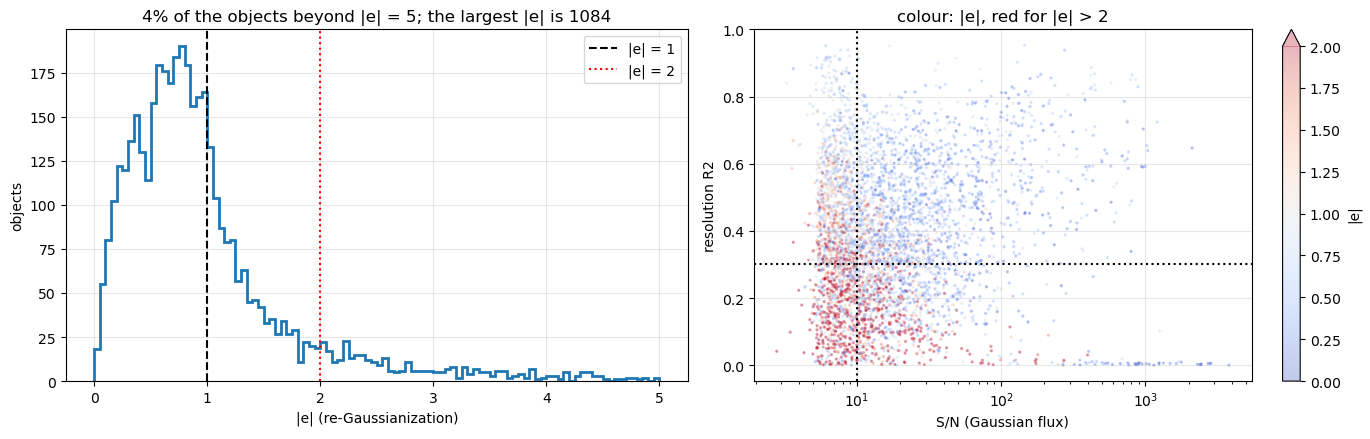

shape sample: 1690 galaxies, 14.0 per arcmin2


In [13]:
e_abs = np.hypot(cat.e1, cat.e2)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ok = cat.good & cat.shape_ok
axes[0].hist(e_abs[ok], bins=100, range=(0, 5), histtype='step', lw=2)
axes[0].axvline(1, c='k', ls='--', label='|e| = 1')
axes[0].axvline(2, c='r', ls=':', label='|e| = 2')
axes[0].set_xlabel('|e| (re-Gaussianization)'); axes[0].set_ylabel('objects'); axes[0].legend()
axes[0].set_title(f'{(e_abs[ok] > 5).mean():.0%} of the objects beyond |e| = 5; the largest |e| is {e_abs[ok].max():.0f}')
points = axes[1].scatter(cat.snr[ok], cat.R2[ok], s=2, alpha=0.3, c=e_abs[ok], cmap='coolwarm', vmin=0, vmax=2)
plt.colorbar(points, ax=axes[1], label='|e|', extend='max')
axes[1].set_xscale('log'); axes[1].axvline(10, c='k', ls=':'); axes[1].axhline(0.3, c='k', ls=':')
axes[1].set_xlabel('S/N (Gaussian flux)'); axes[1].set_ylabel('resolution R2'); axes[1].set_title('colour: |e|, red for |e| > 2')
plt.tight_layout(); plt.show()

SHAPE_CUT = lambda c: c.good & c.shape_ok & (c.snr > 10) & (c.R2 > 0.3) & (np.hypot(c.e1, c.e2) < 2)
gal = SHAPE_CUT(cat)
print(f'shape sample: {gal.sum()} galaxies, {gal.sum() / area:.1f} per arcmin2')

### Questions

1. The observed distortion never reaches 1, yet the table shows many PSF-corrected distortions with $|e| > 1$. How can $|e|$ be larger than 1? (Take a round PSF in the correction formula, and look at how the errors in the table depend on $R_2$.)
2. Where in the S/N–resolution plane do the wild shapes ($|e| > 2$) sit? Why there?
3. What does the resolution cut $R_2 > 0.3$ remove, besides badly measured shapes?
4. A real galaxy has $|e| < 1$, yet the shape cut keeps $|e| < 2$. Why not cut at 1? And why cut at all? (Think about what a shear does to the distribution of $e$ near the cut, and compare the histogram near $|e| = 1$ and near $|e| = 2$.)

## 6. Galaxy properties

### Size and magnitude, stars and galaxies

The moments include the PSF, so a star has $T/T_{\rm PSF} = 1$: the stars form a horizontal line in the size–magnitude plane, and galaxies lie above it. We select bright stars from that line, to be used in Section 7.

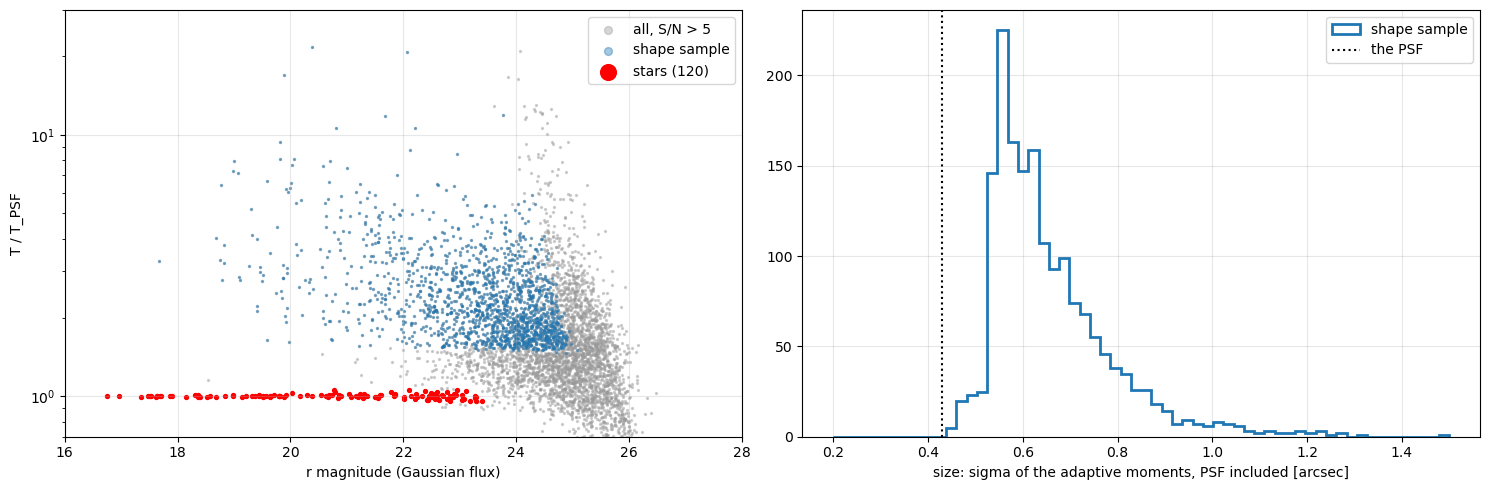

In [14]:
STAR_CUT = lambda c: c.good & (c.snr > 50) & (np.abs(c.T_ratio - 1) < 0.06)
star = STAR_CUT(cat)
ok = cat.good & (cat.snr > 5)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(cat.mag[ok], cat.T_ratio[ok], s=2, c='0.6', alpha=0.4, label='all, S/N > 5')
axes[0].scatter(cat.mag[gal], cat.T_ratio[gal], s=2, c='tab:blue', alpha=0.4, label='shape sample')
axes[0].scatter(cat.mag[star], cat.T_ratio[star], s=8, c='r', label=f'stars ({star.sum()})')
axes[0].set_yscale('log'); axes[0].set_ylim(0.7, 30); axes[0].set_xlim(16, 28)
axes[0].set_xlabel(f'{BAND} magnitude (Gaussian flux)'); axes[0].set_ylabel('T / T_PSF'); axes[0].legend(markerscale=4)
axes[1].hist(cat.sigma_obs[gal], bins=60, range=(0.2, 1.5), histtype='step', lw=2, label='shape sample')
axes[1].axvline(np.sqrt(T_psf.median() / 2) * PIXEL_SCALE, c='k', ls=':', label='the PSF')
axes[1].set_xlabel('size: sigma of the adaptive moments, PSF included [arcsec]'); axes[1].legend()
plt.tight_layout(); plt.show()

### Number counts and shape noise

The number of objects per magnitude rises steeply towards faint magnitudes, until the catalogue becomes incomplete and the counts turn over. We count all our objects with S/N > 5, and the shape sample. We also compute the rms distortion of the shape sample, $e_{\rm rms}$, which gives the responsivity $\mathcal{R} = 1 - e_{\rm rms}^2$ used in Section 7.

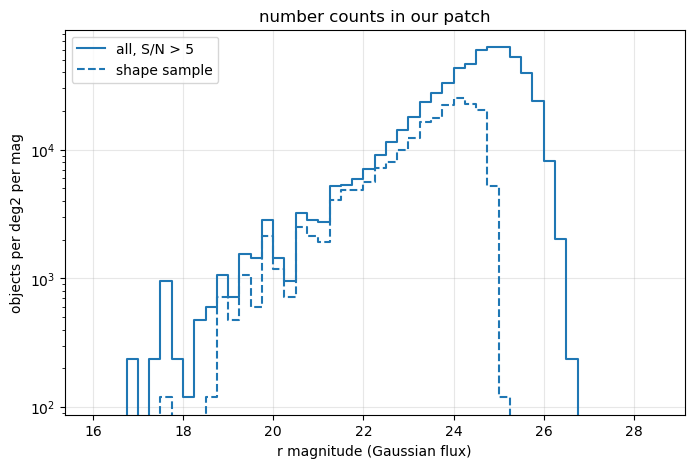

shape sample: e_rms per component 0.511, responsivity 1 - e_rms^2 = 0.739


In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
bins = np.arange(16, 29, 0.25)
patch_area_deg2 = area / 3600
for m, label, ls in [(cat.mag[cat.good & (cat.snr > 5)], 'all, S/N > 5', '-'), (cat.mag[gal], 'shape sample', '--')]:
    h, _ = np.histogram(m, bins)
    ax.step(bins[:-1], h / patch_area_deg2 / 0.25, where='post', color='tab:blue', ls=ls, label=label)
ax.set_yscale('log'); ax.set_xlabel(f'{BAND} magnitude (Gaussian flux)'); ax.set_ylabel('objects per deg2 per mag'); ax.legend()
ax.set_title('number counts in our patch')
plt.show()

e_rms = np.sqrt(0.5 * (cat.e1[gal]**2 + cat.e2[gal]**2).mean())
print(f'shape sample: e_rms per component {e_rms:.3f}, responsivity 1 - e_rms^2 = {1 - e_rms**2:.3f}')

### Questions

1. Down to which magnitude is our catalogue complete? Where do the shape cuts start removing galaxies?
2. Convert $e_{\rm rms}$ to the shape noise per component of shear, $\sigma_g = e_{\rm rms} / 2\mathcal{R}$. LSST forecasts often assume 0.26. Why is ours larger? (Hint: what besides the intrinsic shapes scatters a measured shape?)

## 7. Patterns in the averaged shapes

Weak lensing is measured by averaging. The mean shear of a sample of $N$ galaxies is known to $\sigma_e / (2\mathcal{R}\sqrt N)$ from shape noise alone, while cosmic shear over a few arcminutes to a degree is of order $10^{-2}$ to $10^{-3}$. Two systematics add to it:

- **PSF leakage:** if the PSF correction is imperfect, part of the PSF ellipticity stays in the galaxy shapes: $\langle g\rangle = \alpha\, g_{\rm PSF} + \dots$
- **Additive bias** $c$: any other spurious mean shear, for example from the detector, the background or the masks.

We look at the PSF model against the stars of our patch, then at the mean shape of its galaxies. Distortions are converted to shears with $g = e / 2\mathcal{R}$ for the galaxies, and $g \approx e/2$ for the PSF.

### 7a. The PSF model against the stars

At each star, `HsmSourceMoments` measures the star itself and `HsmPsfMoments` the PSF model there. If the model is right, the two agree, and the residuals are noise.

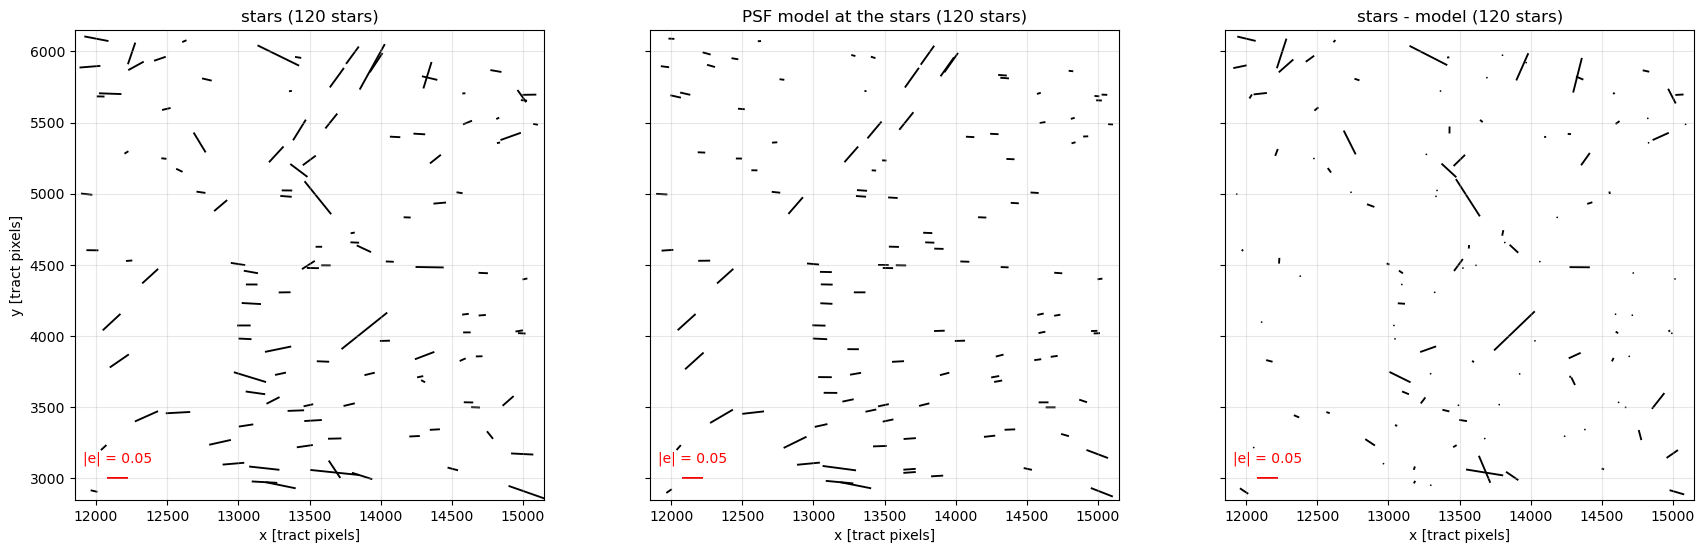

e1: stars +0.0211, model +0.0192, residual +0.0019 +- 0.0017
e2: stars +0.0048, model +0.0052, residual -0.0004 +- 0.0022


In [16]:
s = cat[star]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
L = 3000                                                    # whisker length per unit e, in pixels
for ax, (e1, e2, title) in zip(axes, [(s.e1_obs, s.e2_obs, 'stars'), (s.e1_psf, s.e2_psf, 'PSF model at the stars'),
                                       (s.e1_obs - s.e1_psf, s.e2_obs - s.e2_psf, 'stars - model')]):
    e, th = np.hypot(e1, e2), 0.5 * np.arctan2(e2, e1)
    ax.quiver(s.x, s.y, L * e * np.cos(th), L * e * np.sin(th), angles='xy', scale_units='xy', scale=1,
              headwidth=0, headlength=0, headaxislength=0, pivot='middle', width=0.004)
    ax.quiver([bbox.x.start + 300], [bbox.y.start + 150], [L * 0.05], [0], angles='xy', scale_units='xy', scale=1,
              headwidth=0, headlength=0, headaxislength=0, pivot='middle', width=0.004, color='r')
    ax.text(bbox.x.start + 300, bbox.y.start + 260, '|e| = 0.05', color='r', ha='center')
    ax.set_xlim(EXTENT[:2]); ax.set_ylim(EXTENT[2:]); ax.set_aspect('equal'); ax.set_title(f'{title} ({len(s)} stars)')
    ax.set_xlabel('x [tract pixels]')
axes[0].set_ylabel('y [tract pixels]'); plt.tight_layout(); plt.show()

for k in '12':
    r = s[f'e{k}_obs'] - s[f'e{k}_psf']
    print(f'e{k}: stars {s[f"e{k}_obs"].mean():+.4f}, model {s[f"e{k}_psf"].mean():+.4f}, '
          f'residual {r.mean():+.4f} +- {r.std() / np.sqrt(len(r)):.4f}')

### 7b. The mean galaxy shape in our patch

We average the shape sample over the patch, and over a 4 × 4 grid of sub-patches (2.75′ each), and compare with the PSF ellipticity at the galaxies' positions.

In the two maps of the first row, the **colour** is the mean shear $\langle g_1\rangle$ or $\langle g_2\rangle$ of the galaxies in each sub-patch, on a scale from −0.05 to +0.05 (sub-patches beyond it take the end colours). From shape noise alone, each mean has an error $\sigma_g/\sqrt{N}$, where $N$ is the number of shape-sample galaxies in the sub-patch and $\sigma_g$ the *shape noise*: the scatter of the shears of single galaxies, per component, shown in the top-right panel. The printed $\chi^2$ is the sum over the sub-patches of $\left(\langle g\rangle / (\sigma_g/\sqrt{N})\right)^2$; if shape noise were all, each term would be about 1.

The second row shows the same average for the PSF model's shear at the same galaxies, $g_{\rm PSF} = e_{\rm PSF}/2$; the numbers give the means. If part of the PSF leaked into the shapes, $\langle g\rangle = \alpha\, g_{\rm PSF} + c$, the galaxy maps would follow the PSF maps. The bottom-right panel tests this directly: one point per sub-patch, with the correlation coefficient $r$ and the slope $\alpha$ of a straight line weighted by the errors.

patch mean: g1 = -0.0045, g2 = -0.0035, +- 0.0084 (shape noise);  PSF at the galaxies: g1 = +0.0093, g2 = +0.0026
mean g1: chi2 = 22.2 for 16 sub-patches
g1: PSF means of the sub-patches -0.0013 to +0.0199; correlation with the galaxy means r = +0.16; slope alpha = +1.66 +- 1.80
mean g2: chi2 = 27.0 for 16 sub-patches
g2: PSF means of the sub-patches -0.0072 to +0.0149; correlation with the galaxy means r = +0.22; slope alpha = +1.61 +- 1.51


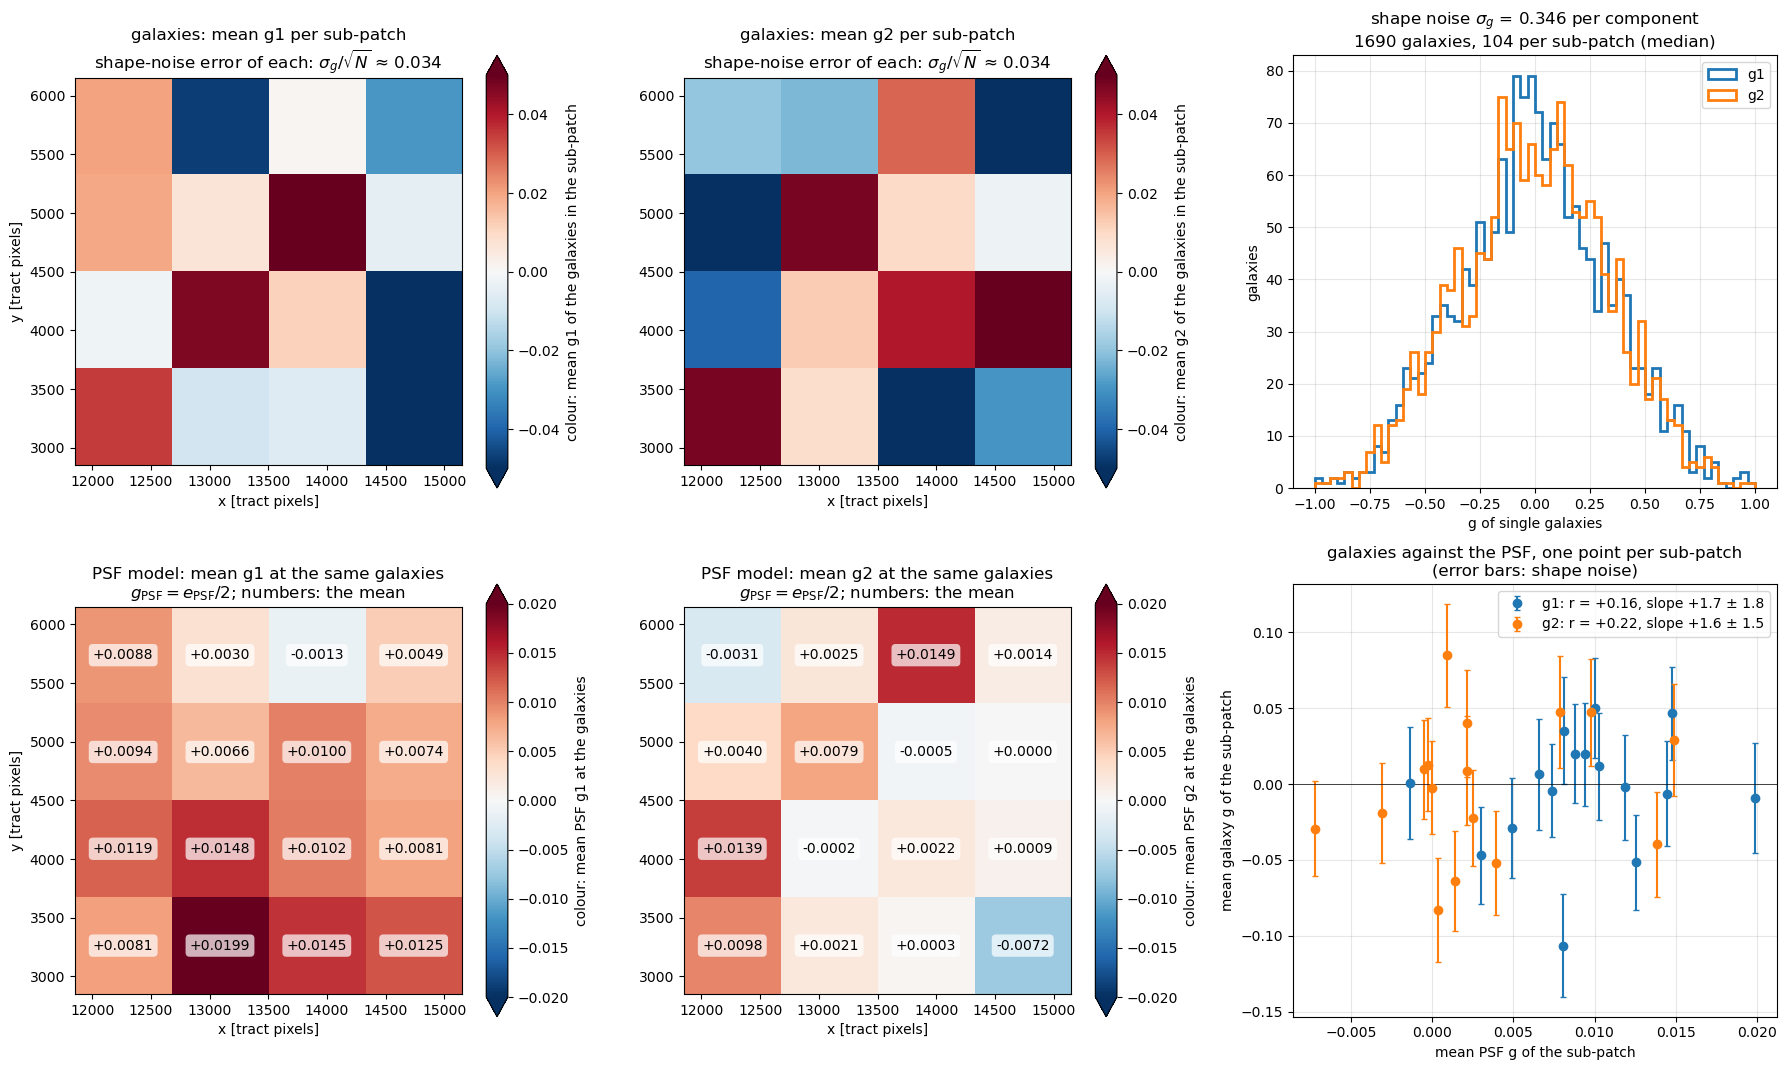

In [17]:
g = cat[gal]
R = 1 - e_rms**2
g1, g2 = g.e1 / (2 * R), g.e2 / (2 * R)
p1, p2 = g.e1_psf / 2, g.e2_psf / 2                # the PSF model's shear at the same galaxies
sig = np.sqrt(0.5 * (g1.var() + g2.var()))
print(f'patch mean: g1 = {g1.mean():+.4f}, g2 = {g2.mean():+.4f}, +- {sig / np.sqrt(len(g)):.4f} (shape noise);  '
      f'PSF at the galaxies: g1 = {g.e1_psf.mean() / 2:+.4f}, g2 = {g.e2_psf.mean() / 2:+.4f}')

NSUB = 4
ix = np.clip(((g.x - bbox.x.start) / 3300 * NSUB).astype(int), 0, NSUB - 1)
iy = np.clip(((g.y - bbox.y.start) / 3300 * NSUB).astype(int), 0, NSUB - 1)
n_sub = np.array([[((ix == i) & (iy == j)).sum() for i in range(NSUB)] for j in range(NSUB)])   # galaxies per sub-patch
err_sub = sig / np.sqrt(np.median(n_sub))                     # the typical shape-noise error of a sub-patch mean


def sub_means(val):
    # the mean of `val` over the galaxies of each sub-patch, as a NSUB x NSUB map (row = y, column = x)
    m = np.full((NSUB, NSUB), np.nan)
    for i in range(NSUB):
        for j in range(NSUB):
            m[j, i] = val[(ix == i) & (iy == j)].mean()
    return m


def label_cells(ax, values, fmt):
    for i in range(NSUB):
        for j in range(NSUB):
            ax.text(EXTENT[0] + (i + 0.5) * 3300 / NSUB, EXTENT[2] + (j + 0.5) * 3300 / NSUB, fmt(values[j, i]), ha='center', va='center',
                    bbox=dict(boxstyle='round', fc='white', alpha=0.7, lw=0))


fig, axes = plt.subplots(2, 3, figsize=(18, 10.8))
err = (sig / np.sqrt(n_sub)).ravel()                          # the shape-noise error of each sub-patch mean
for col, (val, psf, name) in enumerate([(g1, p1, 'g1'), (g2, p2, 'g2')]):
    m, mp = sub_means(val), sub_means(psf)
    z = m / (sig / np.sqrt(n_sub))                            # the mean / its error, for the chi2
    ax = axes[0, col]
    im = ax.imshow(m, origin='lower', cmap='RdBu_r', vmin=-0.05, vmax=0.05, extent=EXTENT)
    plt.colorbar(im, ax=ax, extend='both', label=f'colour: mean {name} of the galaxies in the sub-patch')
    ax.set_title(f'galaxies: mean {name} per sub-patch\n' + r'shape-noise error of each: $\sigma_g/\sqrt{N}$' + f' ≈ {err_sub:.3f}')
    ax = axes[1, col]
    im = ax.imshow(mp, origin='lower', cmap='RdBu_r', vmin=-0.02, vmax=0.02, extent=EXTENT)
    label_cells(ax, mp, lambda v: f'{v:+.4f}')
    plt.colorbar(im, ax=ax, extend='both', label=f'colour: mean PSF {name} at the galaxies')
    ax.set_title(f'PSF model: mean {name} at the same galaxies\n' + r'$g_{\rm PSF} = e_{\rm PSF}/2$; numbers: the mean')
    print(f'mean {name}: chi2 = {np.nansum(z**2):.1f} for {NSUB**2} sub-patches')
    # do the galaxy means follow the PSF means? correlation, and a weighted straight line  <g> = alpha g_PSF + c
    x, y = mp.ravel(), m.ravel()
    A, w = np.c_[x, np.ones_like(x)], 1 / err**2
    cov = np.linalg.inv(A.T @ (A * w[:, None])); alpha, c = cov @ (A.T @ (w * y))
    r = np.corrcoef(x, y)[0, 1]
    axes[1, 2].errorbar(x, y, err, fmt='o', capsize=2, label=f'{name}: r = {r:+.2f}, slope {alpha:+.1f} ± {np.sqrt(cov[0, 0]):.1f}')
    print(f'{name}: PSF means of the sub-patches {x.min():+.4f} to {x.max():+.4f}; correlation with the galaxy means r = {r:+.2f}; '
          f'slope alpha = {alpha:+.2f} +- {np.sqrt(cov[0, 0]):.2f}')
for ax in axes[:, :2].ravel():
    ax.set_xlabel('x [tract pixels]'); ax.grid(False)
for ax in axes[:, 0]:
    ax.set_ylabel('y [tract pixels]')
axes[0, 2].hist(g1, bins=60, range=(-1, 1), histtype='step', lw=2, label='g1'); axes[0, 2].hist(g2, bins=60, range=(-1, 1), histtype='step', lw=2, label='g2')
axes[0, 2].set_xlabel('g of single galaxies'); axes[0, 2].set_ylabel('galaxies'); axes[0, 2].legend()
axes[0, 2].set_title(r'shape noise $\sigma_g$' + f' = {sig:.3f} per component\n{len(g)} galaxies, {np.median(n_sub):.0f} per sub-patch (median)')
axes[1, 2].axhline(0, c='k', lw=0.5); axes[1, 2].legend()
axes[1, 2].set_xlabel('mean PSF g of the sub-patch'); axes[1, 2].set_ylabel('mean galaxy g of the sub-patch')
axes[1, 2].set_title('galaxies against the PSF, one point per sub-patch\n(error bars: shape noise)')
plt.tight_layout(); plt.show()

### Questions

1. Is the PSF model a good description of the stars in our patch? How large are the residuals compared with the PSF ellipticity itself?
2. Is the mean shear of our patch consistent with zero? Compare its error with the expected size of cosmic shear on these scales.
3. Is the scatter of the sub-patch means larger than shape noise predicts? (With 16 sub-patches, $\chi^2$ should be about $16 \pm 6$.) Name two things, one physical and one instrumental, that can make the mean shear vary from one sub-patch to another.

## 8. Going further

These exercises need some code. Each one builds on the sections named in its title, and uses the objects made there. Where an exercise reruns a step of the pipeline, build new tasks with their own schema in new cells, so that the rest of the notebook stays unchanged.

**Exercise 1. Detection and deblending** (Sections 3 to 5)
1. Rerun the detection with `thresholdValue = 3` and `10`. How does the number of footprints change? Which objects appear or disappear? Are the new ones real? (With `thresholdPolarity = 'both'`, the task also finds *negative* footprints, which can only be noise.)
2. Rerun Section 5 without deblending: measure the parents instead. Which galaxy properties change most?
3. What fraction of the objects we measure are children of a blend? (The catalogue `cat` of Section 5 has a column `is_child`.) Would you expect more or fewer blends in a deeper image, or with a sharper PSF?

**Exercise 2. What limits the shape sample** (Sections 2, 5 and 6)
1. Count how many of the measured objects each part of `SHAPE_CUT` removes (the flags, S/N > 10, $R_2 > 0.3$, $|e| < 2$), on its own and one after the other. Which matters most?
2. Section 2 found cells along the gaps between detectors with a sharper PSF but more noise (the array `gaps`). Compare the number of shape-sample galaxies per cell, and their median $R_2$, inside and outside them. Which effect wins? (A galaxy at tract pixel $(x, y)$ lies in the cell with row `int(y - Y0) // CELL` and column `int(x - X0) // CELL`.)
3. **Another band, another field:** set `BAND = 'i'`, or move to COSMOS (`RA, DEC = 150.1, 2.1`) or a Wide-Fast-Deep tract, and rerun. How do the PSF, the depth and the density of the shape sample change?